# 78. The Reconstructed Key Book: Visual Approximation

A visual representation of what the original "key book" of the Voynich code might have looked like — the reference table that the code's user would consult to compose or read entries.

Based on the structural dictionary of notebook 77.

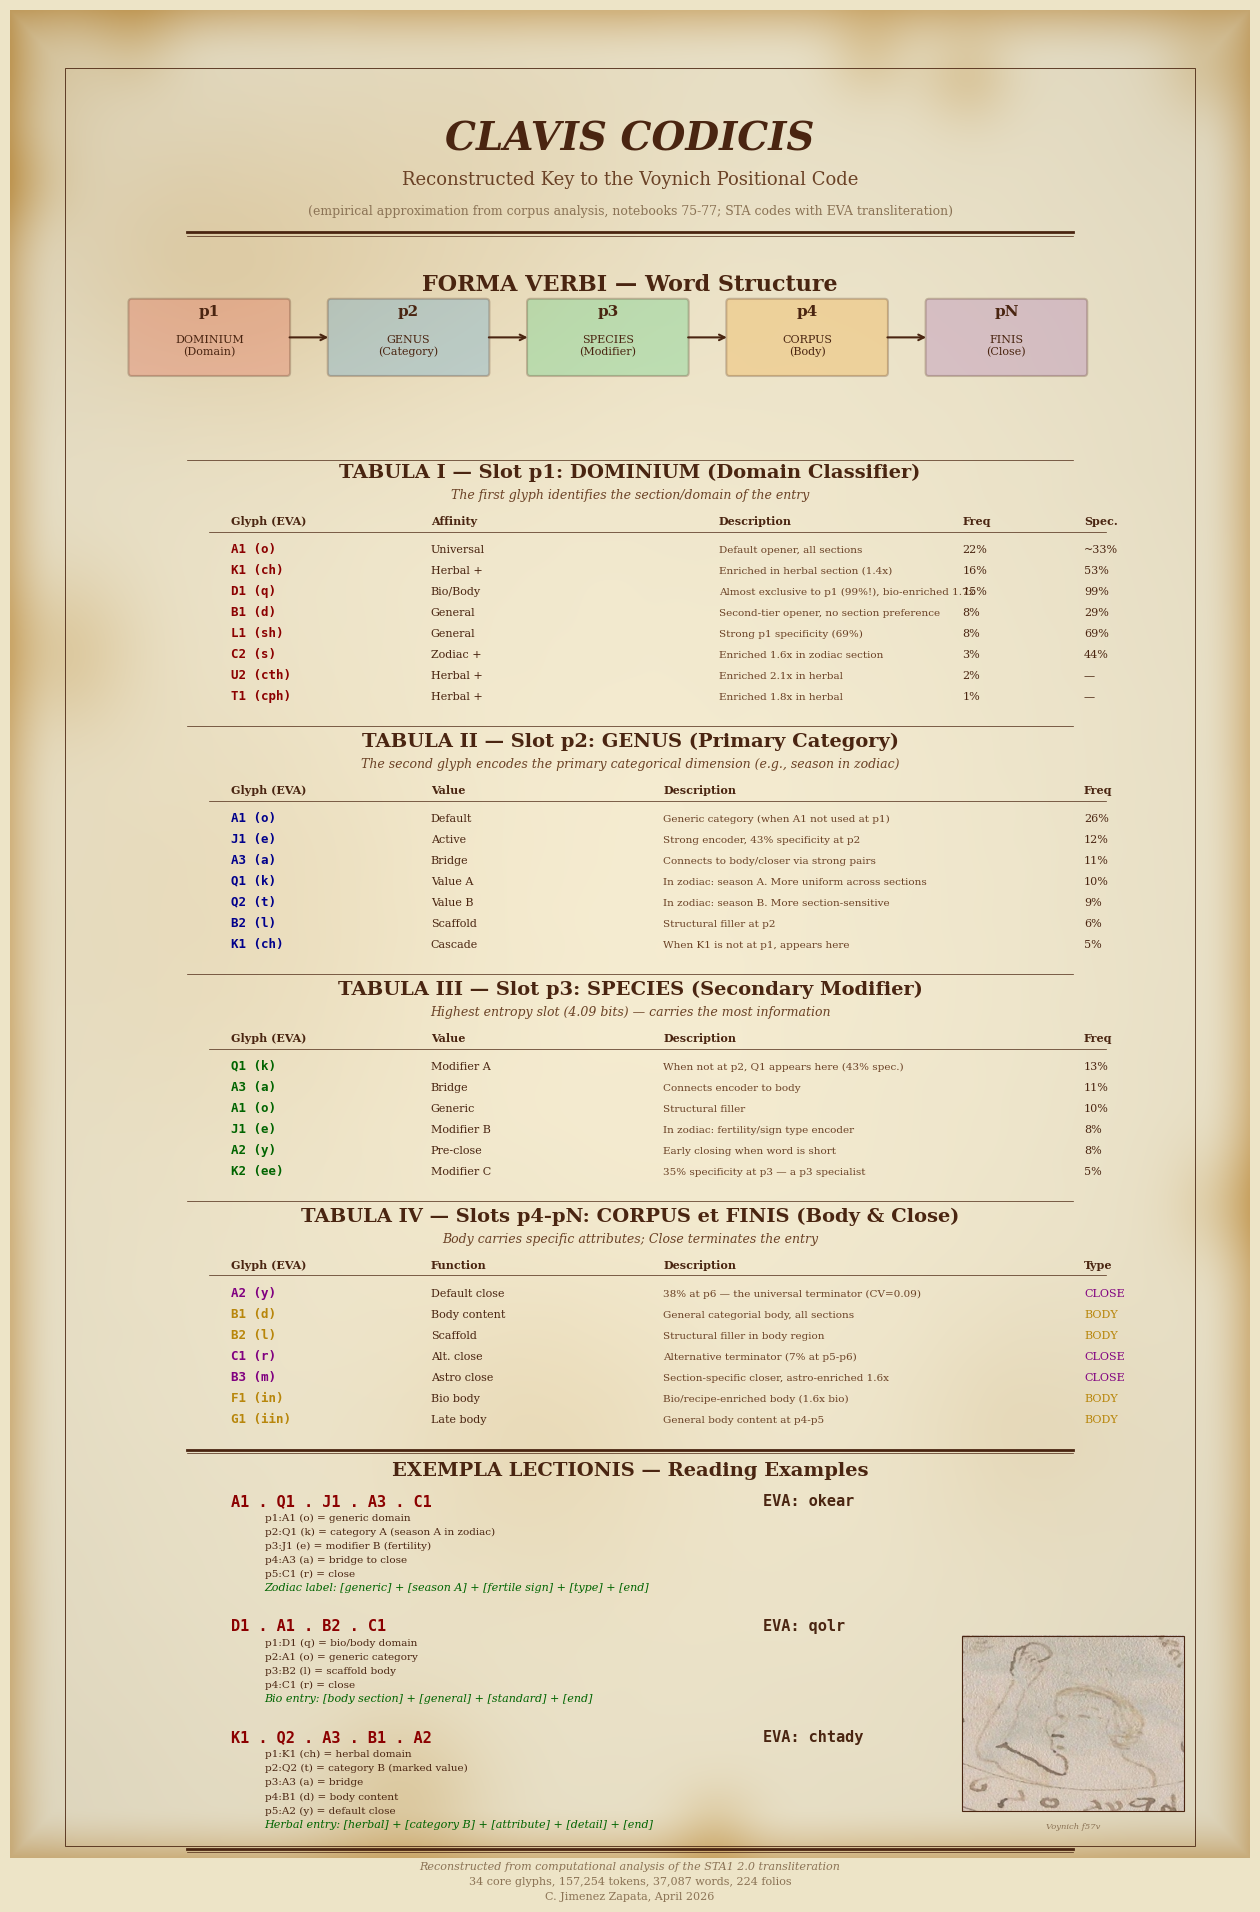

Saved: key_book_reconstructed.png and .pdf


In [23]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import numpy as np

# ══════════════════════════════════════════════════════════════
# Parchment background — procedural (no external image)
# ══════════════════════════════════════════════════════════════
def parchment_texture(h=1000, w=720, seed=20260412):
    """Cream base with soft noise, radial darkening, aging stains, and an
    IRREGULAR torn-edge (deckle) border — not a straight rectangular band."""
    from scipy.ndimage import gaussian_filter
    rng = np.random.default_rng(seed)
    base = np.array([245, 236, 209]) / 255.0
    tex = np.ones((h, w, 3)) * base

    # Low-frequency noise for overall tonal variation
    noise = rng.normal(0, 0.02, (h, w, 1))
    noise = gaussian_filter(noise, sigma=(10, 10, 0))
    tex += noise

    # Gentle radial darkening (corners ~6% darker than center)
    yy, xx = np.mgrid[0:h, 0:w]
    cy, cx = h / 2, w / 2
    r = np.sqrt(((yy - cy) / cy) ** 2 + ((xx - cx) / cx) ** 2)
    shade = np.clip(1.0 - 0.06 * r ** 1.6, 0.0, 1.0)[..., None]
    tex *= shade

    # Aging stains — soft brown patches (iron-gall oxidation tint)
    # We shift toward brown (darken blue/green more than red) rather than
    # darkening all channels equally, which looked too black.
    brown_tint = np.array([-0.03, -0.06, -0.10])  # red barely changes, blue drops most
    for _ in range(6):
        sy = rng.integers(h * 0.08, h * 0.92)
        sx = rng.integers(w * 0.08, w * 0.92)
        rad = rng.integers(40, 100)
        strength = rng.uniform(0.5, 1.0)
        dist2 = (yy - sy) ** 2 + (xx - sx) ** 2
        mask = np.exp(-dist2 / (2 * rad ** 2))
        tex += strength * mask[..., None] * brown_tint[None, None, :]

    # ── Irregular deckle edge ──
    # Distance from each pixel to the nearest image edge, modulated by
    # 2D low-frequency noise so the dark border has a torn, uneven width.
    dist_edge = np.minimum(np.minimum(yy, h - 1 - yy),
                           np.minimum(xx, w - 1 - xx)).astype(float)
    edge_noise = gaussian_filter(rng.normal(0, 1, (h, w)), sigma=18) * 14
    dist_mod = dist_edge + edge_noise
    edge_px = 28  # mean deckle-band width
    band = np.clip(1.0 - dist_mod / edge_px, 0, 1) ** 1.8
    # Deckle edge in warm brown (darkens blue/green more than red)
    deckle_tint = np.array([-0.08, -0.16, -0.26])
    tex += band[..., None] * deckle_tint[None, None, :]

    # Outer ragged fade: brownish worn spots near the edges
    brown_edge = np.array([-0.04, -0.08, -0.14])
    for _ in range(10):
        side = rng.integers(0, 4)
        if side == 0:    sy, sx = rng.integers(0, 40), rng.integers(0, w)
        elif side == 1:  sy, sx = rng.integers(h-40, h), rng.integers(0, w)
        elif side == 2:  sy, sx = rng.integers(0, h), rng.integers(0, 40)
        else:            sy, sx = rng.integers(0, h), rng.integers(w-40, w)
        rad = rng.integers(18, 38)
        dist2 = (yy - sy) ** 2 + (xx - sx) ** 2
        mask = np.exp(-dist2 / (2 * rad ** 2))
        tex += mask[..., None] * brown_edge[None, None, :]

    return np.clip(tex, 0, 1)


# ══════════════════════════════════════════════════════════════
# STA1 → EVA mapping (from Zandbergen STA1 v1.03, Sep 2025)
# EVA is the standard Voynichological ASCII representation of
# the actual glyphs — we show both codes side by side.
# ══════════════════════════════════════════════════════════════
STA_TO_EVA = {
    # A family
    'A1': 'o',  'A2': 'y',  'A3': 'a',  'A4': 'u',
    # B family
    'B1': 'd',  'B2': 'l',  'B3': 'm',  'B4': 'g',  'B5': 'j',  'B6': 'z',
    # C family
    'C1': 'r',  'C2': 's',
    # D family
    'D1': 'q',
    # E family
    'E1': 'i',  'E2': 'n',
    # F family
    'F1': 'in', 'F2': 'ii', 'F3': 'ir',
    # G family
    'G1': 'iin','G2': 'iii','G3': 'iir',
    # H family
    'H1': 'iiin','H2': 'iiiin','H3': 'iiir',
    # J family
    'J1': 'e',  'J2': 'b',
    # K family
    'K1': 'ch', 'K2': 'ee',
    # L family
    'L1': 'sh',
    # M family
    'M1': 'eee','M2': 'eeb',
    # N family
    'N1': 'eeee','N2':'eeeb',
    # P family
    'P1': 'p',  'P2': 'f',
    # Q family
    'Q1': 'k',  'Q2': 't',
    # T family
    'T1': 'cph','T2': 'cfh',
    # U family
    'U1': 'ckh','U2': 'cth',
    # V family
    'V1': 'cphh','V2': 'cfhh',
    # W family
    'W1': 'ckhh','W2': 'cthh',
}

def label(sta):
    """Render a STA code as 'STA (eva)' using the mapping above."""
    eva = STA_TO_EVA.get(sta)
    return f'{sta} ({eva})' if eva else sta

# ══════════════════════════════════════════════════════════════
# THE RECONSTRUCTED KEY BOOK — Page 1: Word Structure
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(16, 24))
ax.set_xlim(-6, 106)
ax.set_ylim(-9, 149)
ax.axis('off')

fig.patch.set_facecolor('#ede4c7')
ax.set_facecolor('#f5ecd0')

# Parchment texture as background image (fills the full canvas so the torn
# deckle edge sits well OUTSIDE the content area — no text lands on the band)
_tex = parchment_texture()
ax.imshow(_tex, extent=[-6, 106, -9, 149], aspect='auto', zorder=0, interpolation='bilinear')

# Single thin decorative ruling — kept well inside the deckle edge so it
# reads as a medieval text-block rule, not as a picture-frame moulding
rect = plt.Rectangle((-1, -8), 102, 152,
                      fill=False, edgecolor='#4a2511', linewidth=0.6, zorder=1)
ax.add_patch(rect)


# ── Title ──
ax.text(50, 137, 'CLAVIS CODICIS', ha='center', fontsize=28,
        fontfamily='serif', fontweight='bold', color='#4a2511',
        fontstyle='italic')
ax.text(50, 134, 'Reconstructed Key to the Voynich Positional Code',
        ha='center', fontsize=13, fontfamily='serif', color='#6b4226')
ax.text(50, 131.5, '(empirical approximation from corpus analysis, notebooks 75-77; STA codes with EVA transliteration)',
        ha='center', fontsize=9, fontfamily='serif', color='#8b7355')

ax.plot([10, 90], [130, 130], color='#4a2511', linewidth=2)
ax.plot([10, 90], [129.7, 129.7], color='#4a2511', linewidth=0.5)

# ── Word Structure Diagram ──
y_struct = 125
ax.text(50, y_struct, 'FORMA VERBI — Word Structure', ha='center',
        fontsize=16, fontfamily='serif', fontweight='bold', color='#4a2511')

slot_info = [
    ('p1', 'DOMINIUM\n(Domain)', '#e74c3c', 12),
    ('p2', 'GENUS\n(Category)', '#3498db', 30),
    ('p3', 'SPECIES\n(Modifier)', '#2ecc71', 48),
    ('p4', 'CORPUS\n(Body)', '#f39c12', 66),
    ('pN', 'FINIS\n(Close)', '#9b59b6', 84),
]

y_box = 118
box_w, box_h = 14, 6
for slot, lbl, color, x in slot_info:
    rect = FancyBboxPatch((x - box_w/2, y_box), box_w, box_h,
                           boxstyle='round,pad=0.3', facecolor=color,
                           edgecolor='#4a2511', linewidth=1.5, alpha=0.25)
    ax.add_patch(rect)
    ax.text(x, y_box + box_h - 1.2, slot, ha='center', fontsize=11,
            fontfamily='serif', fontweight='bold', color='#4a2511')
    ax.text(x, y_box + 1.5, lbl, ha='center', fontsize=8,
            fontfamily='serif', color='#4a2511', linespacing=1.2)

for i in range(len(slot_info) - 1):
    x1 = slot_info[i][3] + box_w/2
    x2 = slot_info[i+1][3] - box_w/2
    ax.annotate('', xy=(x2, y_box + box_h/2), xytext=(x1, y_box + box_h/2),
                arrowprops=dict(arrowstyle='->', color='#4a2511', lw=1.5))

# ── p1 table ──
y = 109
ax.plot([10, 90], [y + 1.5, y + 1.5], color='#4a2511', linewidth=0.5)
ax.text(50, y, 'TABULA I — Slot p1: DOMINIUM (Domain Classifier)',
        ha='center', fontsize=14, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 1.8
ax.text(50, y, 'The first glyph identifies the section/domain of the entry',
        ha='center', fontsize=9, fontfamily='serif', color='#6b4226', fontstyle='italic')

p1_entries = [
    ('A1', 'Universal', 'Default opener, all sections', '22%', '~33%'),
    ('K1', 'Herbal +', 'Enriched in herbal section (1.4x)', '16%', '53%'),
    ('D1', 'Bio/Body', 'Almost exclusive to p1 (99%!), bio-enriched 1.7x', '15%', '99%'),
    ('B1', 'General', 'Second-tier opener, no section preference', '8%', '29%'),
    ('L1', 'General', 'Strong p1 specificity (69%)', '8%', '69%'),
    ('C2', 'Zodiac +', 'Enriched 1.6x in zodiac section', '3%', '44%'),
    ('U2', 'Herbal +', 'Enriched 2.1x in herbal', '2%', '—'),
    ('T1', 'Herbal +', 'Enriched 1.8x in herbal', '1%', '—'),
]

y -= 2.2
cols = [14, 32, 58, 80, 91]
headers = ['Glyph (EVA)', 'Affinity', 'Description', 'Freq', 'Spec.']
for x, h in zip(cols, headers):
    ax.text(x, y, h, fontsize=8, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 0.6
ax.plot([12, 93], [y, y], color='#4a2511', linewidth=0.5)

for glyph, affinity, desc, freq, spec in p1_entries:
    y -= 1.8
    ax.text(cols[0], y, label(glyph), fontsize=9, fontfamily='monospace', fontweight='bold', color='#8b0000')
    ax.text(cols[1], y, affinity, fontsize=8, fontfamily='serif', color='#4a2511')
    ax.text(cols[2], y, desc, fontsize=7.5, fontfamily='serif', color='#6b4226')
    ax.text(cols[3], y, freq, fontsize=8, fontfamily='serif', color='#4a2511')
    ax.text(cols[4], y, spec, fontsize=8, fontfamily='serif', color='#4a2511')

# ── p2 table ──
y -= 4
ax.plot([10, 90], [y + 1.8, y + 1.8], color='#4a2511', linewidth=0.5)
ax.text(50, y, 'TABULA II — Slot p2: GENUS (Primary Category)',
        ha='center', fontsize=14, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 1.8
ax.text(50, y, 'The second glyph encodes the primary categorical dimension (e.g., season in zodiac)',
        ha='center', fontsize=9, fontfamily='serif', color='#6b4226', fontstyle='italic')

p2_entries = [
    ('A1', 'Default', 'Generic category (when A1 not used at p1)', '26%'),
    ('J1', 'Active', 'Strong encoder, 43% specificity at p2', '12%'),
    ('A3', 'Bridge', 'Connects to body/closer via strong pairs', '11%'),
    ('Q1', 'Value A', 'In zodiac: season A. More uniform across sections', '10%'),
    ('Q2', 'Value B', 'In zodiac: season B. More section-sensitive', '9%'),
    ('B2', 'Scaffold', 'Structural filler at p2', '6%'),
    ('K1', 'Cascade', 'When K1 is not at p1, appears here', '5%'),
]

y -= 2.2
cols2 = [14, 32, 53, 91]
for x, h in zip(cols2, ['Glyph (EVA)', 'Value', 'Description', 'Freq']):
    ax.text(x, y, h, fontsize=8, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 0.6
ax.plot([12, 93], [y, y], color='#4a2511', linewidth=0.5)

for glyph, value, desc, freq in p2_entries:
    y -= 1.8
    ax.text(cols2[0], y, label(glyph), fontsize=9, fontfamily='monospace', fontweight='bold', color='#00008b')
    ax.text(cols2[1], y, value, fontsize=8, fontfamily='serif', color='#4a2511')
    ax.text(cols2[2], y, desc, fontsize=7.5, fontfamily='serif', color='#6b4226')
    ax.text(cols2[3], y, freq, fontsize=8, fontfamily='serif', color='#4a2511')

# ── p3 table ──
y -= 4
ax.plot([10, 90], [y + 1.8, y + 1.8], color='#4a2511', linewidth=0.5)
ax.text(50, y, 'TABULA III — Slot p3: SPECIES (Secondary Modifier)',
        ha='center', fontsize=14, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 1.8
ax.text(50, y, 'Highest entropy slot (4.09 bits) — carries the most information',
        ha='center', fontsize=9, fontfamily='serif', color='#6b4226', fontstyle='italic')

p3_entries = [
    ('Q1', 'Modifier A', 'When not at p2, Q1 appears here (43% spec.)', '13%'),
    ('A3', 'Bridge', 'Connects encoder to body', '11%'),
    ('A1', 'Generic', 'Structural filler', '10%'),
    ('J1', 'Modifier B', 'In zodiac: fertility/sign type encoder', '8%'),
    ('A2', 'Pre-close', 'Early closing when word is short', '8%'),
    ('K2', 'Modifier C', '35% specificity at p3 — a p3 specialist', '5%'),
]

y -= 2.2
for x, h in zip(cols2, ['Glyph (EVA)', 'Value', 'Description', 'Freq']):
    ax.text(x, y, h, fontsize=8, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 0.6
ax.plot([12, 93], [y, y], color='#4a2511', linewidth=0.5)

for glyph, value, desc, freq in p3_entries:
    y -= 1.8
    ax.text(cols2[0], y, label(glyph), fontsize=9, fontfamily='monospace', fontweight='bold', color='#006400')
    ax.text(cols2[1], y, value, fontsize=8, fontfamily='serif', color='#4a2511')
    ax.text(cols2[2], y, desc, fontsize=7.5, fontfamily='serif', color='#6b4226')
    ax.text(cols2[3], y, freq, fontsize=8, fontfamily='serif', color='#4a2511')

# ── Closing slots ──
y -= 4
ax.plot([10, 90], [y + 1.8, y + 1.8], color='#4a2511', linewidth=0.5)
ax.text(50, y, 'TABULA IV — Slots p4-pN: CORPUS et FINIS (Body & Close)',
        ha='center', fontsize=14, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 1.8
ax.text(50, y, 'Body carries specific attributes; Close terminates the entry',
        ha='center', fontsize=9, fontfamily='serif', color='#6b4226', fontstyle='italic')

p4_entries = [
    ('A2', 'Default close', '38% at p6 — the universal terminator (CV=0.09)', 'CLOSE'),
    ('B1', 'Body content', 'General categorial body, all sections', 'BODY'),
    ('B2', 'Scaffold', 'Structural filler in body region', 'BODY'),
    ('C1', 'Alt. close', 'Alternative terminator (7% at p5-p6)', 'CLOSE'),
    ('B3', 'Astro close', 'Section-specific closer, astro-enriched 1.6x', 'CLOSE'),
    ('F1', 'Bio body', 'Bio/recipe-enriched body (1.6x bio)', 'BODY'),
    ('G1', 'Late body', 'General body content at p4-p5', 'BODY'),
]

y -= 2.2
for x, h in zip(cols2, ['Glyph (EVA)', 'Function', 'Description', 'Type']):
    ax.text(x, y, h, fontsize=8, fontfamily='serif', fontweight='bold', color='#4a2511')
y -= 0.6
ax.plot([12, 93], [y, y], color='#4a2511', linewidth=0.5)

for glyph, func, desc, typ in p4_entries:
    y -= 1.8
    color = '#800080' if typ == 'CLOSE' else '#b8860b'
    ax.text(cols2[0], y, label(glyph), fontsize=9, fontfamily='monospace', fontweight='bold', color=color)
    ax.text(cols2[1], y, func, fontsize=8, fontfamily='serif', color='#4a2511')
    ax.text(cols2[2], y, desc, fontsize=7.5, fontfamily='serif', color='#6b4226')
    ax.text(cols2[3], y, typ, fontsize=8, fontfamily='serif', color=color)

# ── Example readings ──
y -= 4.5
ax.plot([10, 90], [y + 2.2, y + 2.2], color='#4a2511', linewidth=2)
ax.plot([10, 90], [y + 1.9, y + 1.9], color='#4a2511', linewidth=0.5)
ax.text(50, y, 'EXEMPLA LECTIONIS — Reading Examples', ha='center',
        fontsize=14, fontfamily='serif', fontweight='bold', color='#4a2511')

def eva_word(sta_list):
    """Render a list of STA codes as the EVA word, e.g. ['A1','Q1','J1'] -> 'okey'."""
    return ''.join(STA_TO_EVA.get(s, s) for s in sta_list)

examples = [
    (['A1','Q1','J1','A3','C1'],
     ['p1:A1 (o) = generic domain', 'p2:Q1 (k) = category A (season A in zodiac)',
      'p3:J1 (e) = modifier B (fertility)', 'p4:A3 (a) = bridge to close', 'p5:C1 (r) = close'],
     'Zodiac label: [generic] + [season A] + [fertile sign] + [type] + [end]'),
    (['D1','A1','B2','C1'],
     ['p1:D1 (q) = bio/body domain', 'p2:A1 (o) = generic category',
      'p3:B2 (l) = scaffold body', 'p4:C1 (r) = close'],
     'Bio entry: [body section] + [general] + [standard] + [end]'),
    (['K1','Q2','A3','B1','A2'],
     ['p1:K1 (ch) = herbal domain', 'p2:Q2 (t) = category B (marked value)',
      'p3:A3 (a) = bridge', 'p4:B1 (d) = body content', 'p5:A2 (y) = default close'],
     'Herbal entry: [herbal] + [category B] + [attribute] + [detail] + [end]'),
]

for sta_list, slots, reading in examples:
    y -= 2.6
    sta_str = ' . '.join(sta_list)
    eva_str = eva_word(sta_list)
    ax.text(14, y, sta_str, fontsize=11, fontfamily='monospace', fontweight='bold', color='#8b0000')
    ax.text(62, y, f'EVA: {eva_str}', fontsize=11, fontfamily='monospace', fontweight='bold', color='#4a2511')
    y -= 1.3
    for s in slots:
        ax.text(17, y, s, fontsize=7.5, fontfamily='serif', color='#4a2511')
        y -= 1.2
    ax.text(17, y, reading, fontsize=8, fontfamily='serif', color='#006400', fontstyle='italic')
    y -= 0.8

# ── Footer ──
y -= 2.5
ax.plot([10, 90], [y + 1.5, y + 1.5], color='#4a2511', linewidth=2)
ax.plot([10, 90], [y + 1.2, y + 1.2], color='#4a2511', linewidth=0.5)
ax.text(50, y - 0.3, 'Reconstructed from computational analysis of the STA1 2.0 transliteration',
        ha='center', fontsize=8, fontfamily='serif', color='#8b7355', fontstyle='italic')
ax.text(50, y - 1.6, '34 core glyphs, 157,254 tokens, 37,087 words, 224 folios',
        ha='center', fontsize=8, fontfamily='serif', color='#8b7355')
ax.text(50, y - 2.9, 'C. Jimenez Zapata, April 2026',
        ha='center', fontsize=8, fontfamily='serif', color='#8b7355')


# ── Nymph from f57v as visual reference ──
_nymph = plt.imread('historic/f57v_ninfa_crop.jpg')
# Place in bottom-right corner, inside the border, semi-transparent
ax.imshow(_nymph, extent=[80, 100, -5, 10], aspect='auto', zorder=2,
          alpha=0.85, interpolation='bilinear')
# Thin border around the nymph
ax.add_patch(plt.Rectangle((80, -5), 20, 15,
             fill=False, edgecolor='#4a2511', linewidth=0.8, zorder=3))
ax.text(90, -6.5, 'Voynich f57v', ha='center', fontsize=6,
        fontfamily='serif', color='#8b7355', fontstyle='italic')

plt.savefig('key_book_reconstructed.png', dpi=200, bbox_inches='tight',
            facecolor='#ede4c7', edgecolor='none')
plt.savefig('key_book_reconstructed.pdf', bbox_inches='tight',
            facecolor='#ede4c7', edgecolor='none')
plt.show()

print('Saved: key_book_reconstructed.png and .pdf')
